# PARIS-MC in JAX: testing the code

This notebook shows how to use `parismc.sampler_jax.JaxSampler`, the JAX-native rewrite of the PARIS adaptive importance sampler.

Key differences from the original NumPy-based `Sampler`:

- **PRNG is threaded explicitly** via `jax.random.PRNGKey` (carried inside the state), not a global seed. In this case runs are reproducible and the step is a pure function.
- **Processes live behind a traced boolean `alive` mask** of fixed size `n_proc_max`. Merging flips mask bits instead of resizing arrays, so shapes stay static and the inner step never recompiles.
- **No in-place mutation**: all state is an immutable pytree (`SamplerState`) updated using purely functional programming. This is the JAX way and allows clean `jax.vmap` and `JIT`. 
- **optax** powers the boundary Beta-correction (smooth surrogate + projected Adam), replacing the old Powell/BFGS path. We use gradient information in the local optimization, more efficient and stable. 
- **Hybrid JIT**: a jitted `lax.scan` runs a block of iterations on-device. Clustering and merging happens on host between blocks (`merge_every`). This is a pragmatic approach to keep as much advantage of compiled code as possible while still allowing dynamic control over the number of processes. 

The `log_density_func` must be JAX-traceable: it gets `vmap`-ed over all processes and stays on the GPU. Otherwise the sampler won't work. The `prior_transform` is optional but must also be JAX-traceable if provided. 

In [1]:
import numpy as np
import jax
import jax.numpy as jnp
import optax
import corner
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

jax.config.update("jax_enable_x64", True)

from parismc.sampler_jax import JaxSampler, JaxSamplerConfig

## Define target distribution
A mixture of **20 equal-weight Gaussian peaks** on the unit square `[0, 1]^2`. The centers are placed by **Poisson-disk rejection** so they are mutually well-separated (`>= 0.16`, i.e. ~8 `sigma`) and barely overlap, while staying clear of the boundary. This is a deliberately hard, highly multimodal landscape — exactly where adaptive importance sampling with dynamic merging earns its keep.

The sampler works on the unit cube; use `prior_transform` to map to physical space if needed. The function takes a batch of points `(n, ndim)` and returns log-densities `(n,)`.

The target is an equal-weight mixture of $K = 20$ isotropic Gaussians with common width $\sigma$ and centers $\{\boldsymbol{\mu}_k\}_{k=1}^{K} \subset [0,1]^2$:

$$
p(\mathbf{x}) \;=\; \frac{1}{K}\sum_{k=1}^{K} \mathcal{N}\!\big(\mathbf{x}\,\big|\,\boldsymbol{\mu}_k,\, \sigma^2 \mathbf{I}\big)
\;\propto\; \frac{1}{K}\sum_{k=1}^{K} \exp\!\left(-\frac{\lVert \mathbf{x}-\boldsymbol{\mu}_k\rVert^2}{2\sigma^2}\right).
$$

The sampler only needs the (unnormalized) **log**-density, which we evaluate stably with `logsumexp`:

$$
\log p(\mathbf{x}) \;=\; \operatorname*{logsumexp}_{1 \le k \le K}\!\left(-\frac{\lVert \mathbf{x}-\boldsymbol{\mu}_k\rVert^2}{2\sigma^2}\right) \;+\; \text{const}.
$$

The centers are drawn by **Poisson-disk rejection** so that $\lVert\boldsymbol{\mu}_k-\boldsymbol{\mu}_l\rVert \ge 0.16 \approx 8\sigma$ for all $k\neq l$: the modes are well separated and barely overlap.

In [2]:
ndim = 2
sigma = 0.02            # per-mode width; modes sit ~8 sigma apart so they barely overlap
n_modes = 20

# Place 20 well-separated, non-overlapping modes in [0, 1]^2 by Poisson-disk rejection:
# keep a new random center only if it is >= min_sep from every accepted one.
rng_modes = np.random.default_rng(1)
min_sep, margin = 0.16, 0.06          # >= 8 sigma apart, >= 3 sigma clear of the boundary
modes_list = []
while len(modes_list) < n_modes:
    p = rng_modes.uniform(margin, 1 - margin, size=ndim)
    if all(np.linalg.norm(p - m) > min_sep for m in modes_list):
        modes_list.append(p)
modes = jnp.asarray(np.array(modes_list))   # (n_modes, ndim)

@jax.jit
def log_density(x):
    x = jnp.atleast_2d(x)                            # (n, ndim)
    d = x[:, None, :] - modes[None, :, :]           # (n, n_modes, ndim)
    comp = -0.5 * jnp.sum((d / sigma) ** 2, axis=2)  # (n, n_modes)
    return jax.scipy.special.logsumexp(comp, axis=1) # (n,)

## Seed the sampler

To recover every mode we must *seed* every mode: PARIS refines and **merges** existing processes but never discovers new ones. So we blanket the prior with quasi-uniform points (the original uses Latin Hypercube Sampling; plain uniform is fine here) and keep the highest-density ones as seeds. Here 20000 uniform points + the top 80 cover all 20 modes. We deliberately start with **far more seeds than modes** and let the redundant ones merge away.

In [3]:
rng = np.random.default_rng(0)
lhs_points = rng.uniform(size=(20000, ndim))
lhs_logdens = np.asarray(log_density(jnp.asarray(lhs_points)))

n_seed = 80                                    # > n_modes: deliberately over-seed
top = np.argsort(-lhs_logdens)[:n_seed]
seed_points = lhs_points[top]
seed_logdens = lhs_logdens[top]
init_cov = np.eye(ndim) * (0.9 * sigma) ** 2   # tight initial proposal (~ per-mode width)

# Sanity check: how many of the 20 modes does this seed set actually cover?
modes_np = np.asarray(modes)
covered = np.unique(np.argmin(
    np.linalg.norm(seed_points[:, None, :] - modes_np[None, :, :], axis=2), axis=1))
print(f"seeds cover {covered.size} / {n_modes} modes")

seeds cover 20 / 20 modes


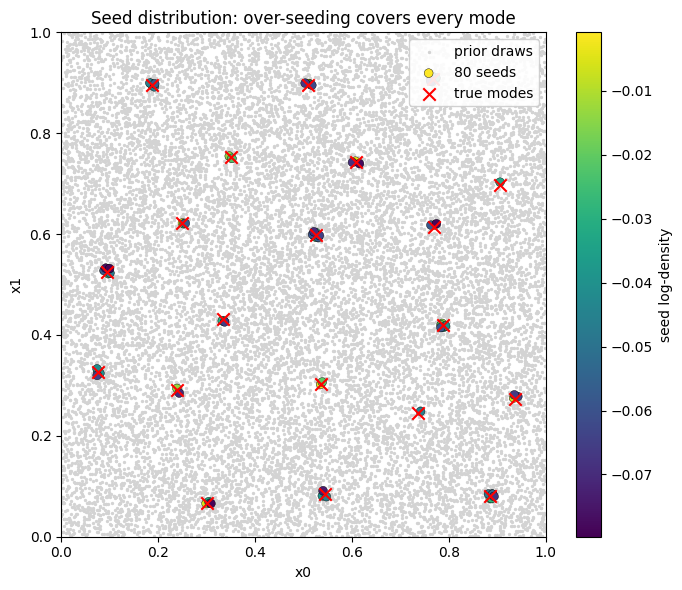

In [4]:
# Visualize where the seeds land relative to the true modes.
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(lhs_points[:, 0], lhs_points[:, 1], s=2, c="lightgray",
           label="prior draws")
sd = ax.scatter(seed_points[:, 0], seed_points[:, 1], c=seed_logdens, s=40,
                cmap="viridis", edgecolor="k", linewidth=0.3, zorder=3,
                label=f"{n_seed} seeds")
ax.scatter(modes_np[:, 0], modes_np[:, 1], marker="x", c="red", s=80, zorder=4,
           label="true modes")
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="x0", ylabel="x1",
       title="Seed distribution: over-seeding covers every mode")
ax.legend(loc="upper right", framealpha=0.9)
fig.colorbar(sd, ax=ax, label="seed log-density")
plt.tight_layout()
plt.show()

## 3. Configure and run

Shape-determining fields (`n_proc_max`, `n_max`, `alpha`, `gamma`, `trail_size`, `integral_num`) should be defined before JIT compiles, as JAX performs optimally if they are static. `n_proc_max` must be `>= n_seed`, and `n_max` must be at least `1 + num_iterations`. The **tight initial covariance** is what keeps neighbouring modes from being merged together before each process has localized onto its own peak.

In [5]:
config = JaxSamplerConfig(
    n_proc_max=96,     # static upper bound on processes (>= n_seed = 80)
    n_max=1200,        # buffer length per process (>= 1 + num_iterations)
    alpha=300,         # sliding-window length for the IS denominator
    gamma=50,          # covariance-update cadence (iterations)
    trail_size=400,    # fixed rejection-sampling budget per process/iteration
    integral_num=1024, # MC samples for the boundary fraction / beta fit
    seed=0,            # PRNGKey seed (threaded, not global)
)

sampler = JaxSampler(ndim=ndim, log_density_func=log_density, config=config)
sampler.init_state(seed_points, seed_logdens, init_cov)

num_iterations, merge_every = 800, 50

def snapshot(state):
    """Host-side picture of the sampler at one clustering step (for the diagnostics below)."""
    alive = np.asarray(state.alive)
    live = np.where(alive)[0]
    nf = int(state.nf)
    samp, w = sampler.get_samples_with_weights(state)
    return dict(
        it=int(state.it),
        n_alive=int(alive.sum()),
        means=np.asarray(state.now_mean)[alive],
        covs=np.asarray(state.now_cov)[alive],
        proc_points=[np.asarray(state.points)[j, :nf] for j in live],
        samples=samp,
        weights=(w / w.sum()) if w.sum() > 0 else w,
        logZ=sampler.log_evidence(state),
    )

# Manual block loop -- identical to sampler.run(), but records a snapshot after every
# host-side merge so we can watch the processes refine and collapse onto the modes.
snapshots = [snapshot(sampler.state)]            # iter 0: the raw seeds, before any merge
state = sampler.state
remaining = num_iterations
while remaining > 0:
    block = min(merge_every, remaining)
    state = sampler._step(state, block)          # jitted lax.scan block (GPU-resident)
    state = sampler._merge_host(state)           # host clustering + alive-mask update
    remaining -= block
    snapshots.append(snapshot(state))
    print(f"iter {int(state.it)} | n_proc {snapshots[-1]['n_alive']} | logZ {snapshots[-1]['logZ']:.5f}")
sampler.state = state

iter 50 | n_proc 20 | logZ -1.06251


iter 100 | n_proc 20 | logZ -1.75228


iter 150 | n_proc 20 | logZ -2.12873


iter 200 | n_proc 20 | logZ -2.39823


iter 250 | n_proc 20 | logZ -2.62240


...

iter 600 | n_proc 20 | logZ -2.78212


iter 650 | n_proc 20 | logZ -2.78213


iter 700 | n_proc 20 | logZ -2.78032


iter 750 | n_proc 20 | logZ -2.77956


iter 800 | n_proc 20 | logZ -2.77877


## 4. Results

Extract weighted posterior samples and the evidence. Watch `n_proc` in the log above collapse from 80 seeds down to **20** — one surviving process per true mode — and stay there once every peak is claimed.

In [6]:
samples, weights = sampler.get_samples_with_weights()
weights = weights / weights.sum()

logZ = sampler.log_evidence()
true_logZ = np.log(n_modes * 2 * np.pi * sigma ** 2)   # 20 unit-amplitude 2D Gaussians

# Match each surviving process to its nearest true mode to count recovered peaks.
alive = np.asarray(state.alive)
means = np.asarray(state.now_mean)[alive]
recovered = np.unique(np.argmin(
    np.linalg.norm(means[:, None, :] - modes_np[None, :, :], axis=2), axis=1)).size

print(f"live processes  : {int(alive.sum())}")
print(f"modes recovered : {recovered} / {n_modes}")
print(f"log Z estimate  : {logZ:.4f}   (analytic: {true_logZ:.4f})")

live processes  : 20
modes recovered : 20 / 20
log Z estimate  : -2.7788   (analytic: -2.9904)


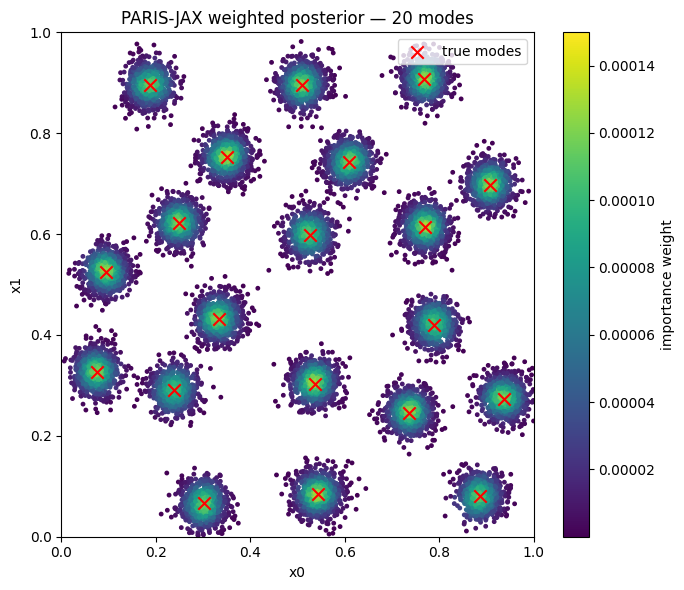

In [7]:
fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(samples[:, 0], samples[:, 1], c=weights, s=6, cmap="viridis")
ax.scatter(modes_np[:, 0], modes_np[:, 1], marker="x", c="red", s=80, label="true modes")
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="x0", ylabel="x1",
       title=f"PARIS-JAX weighted posterior — {n_modes} modes")
ax.legend(loc="upper right")
fig.colorbar(sc, ax=ax, label="importance weight")
plt.tight_layout()
plt.show()

## 5. Diagnostics

The plots below open up the sampler's internals: how the parallel processes refine and merge over the clustering steps, what the optax/Adam boundary correction is doing under the hood, and how the posterior converges. First, a small weighted-`corner` helper used throughout.

In [8]:
def weighted_corner(samples, weights=None, truths=None, fig=None, color="C0", title=None):
    """Thin wrapper around `corner.corner` for importance-weighted samples on [0, 1]^d.

    If `fig` is given it must already contain a d-by-d grid of axes (corner reuses them),
    which lets us drop a corner into one panel of a larger figure.
    """
    d = samples.shape[1]
    rng = [(0.0, 1.0)] * d
    n = len(samples)
    fig = corner.corner(
        samples, weights=weights, fig=fig, color=color,
        labels=[f"$x_{i}$" for i in range(d)], range=rng, bins=40,
        smooth=1.0 if n > 500 else None,
        plot_datapoints=n < 3000, plot_density=True,
        fill_contours=n > 500, levels=(0.5, 0.9),
        hist_kwargs=dict(density=True),
    )
    if truths is not None:
        corner.overplot_points(fig, np.asarray(truths), marker="x", color="red", markersize=6)
    if title is not None:
        fig.suptitle(title, fontsize=12)
    return fig

### 5.1 Refinement and merging across clustering steps

For each recorded clustering step we show two panels:

- **left** — the *live points* in parameter space, colored by surviving process, with each process's current $2\sigma$ proposal-covariance ellipse. This is where you see 80 seeds collapse to 20 processes (one per mode) and then tighten.
- **right** — a `corner` plot of the *intermediate refined posterior* (the importance-weighted samples accumulated so far), with the true modes marked in red.

/Users/bertd/Documents/PhD/LISA/Projects/JAX-waveform/fewtrax/.venv/lib/python3.13/site-packages/corner/core.py:133: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(


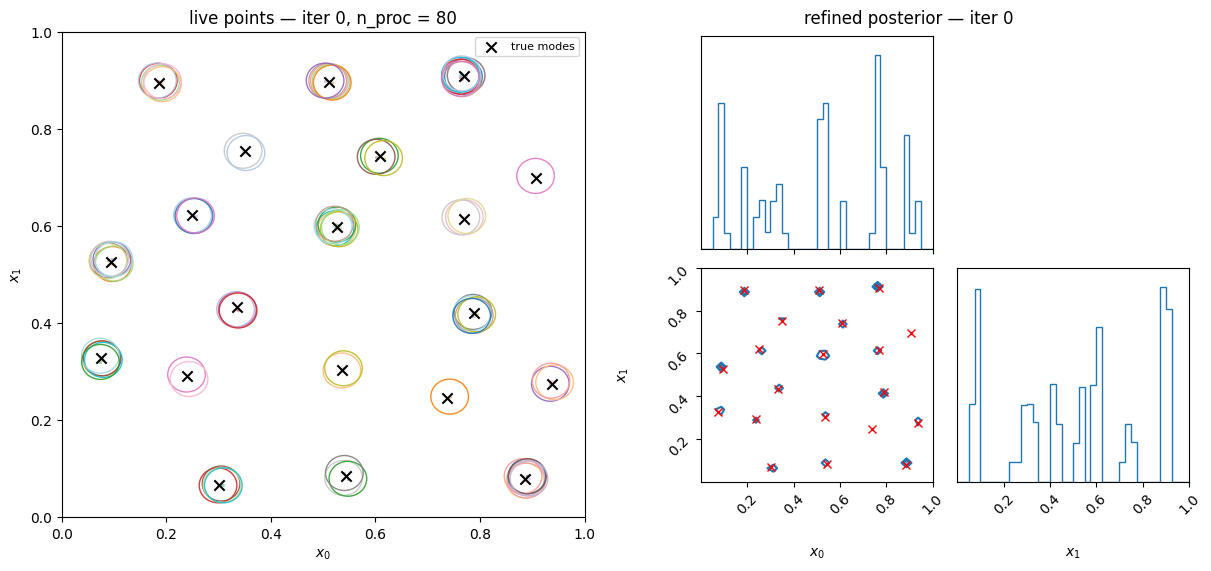

/Users/bertd/Documents/PhD/LISA/Projects/JAX-waveform/fewtrax/.venv/lib/python3.13/site-packages/corner/core.py:133: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(


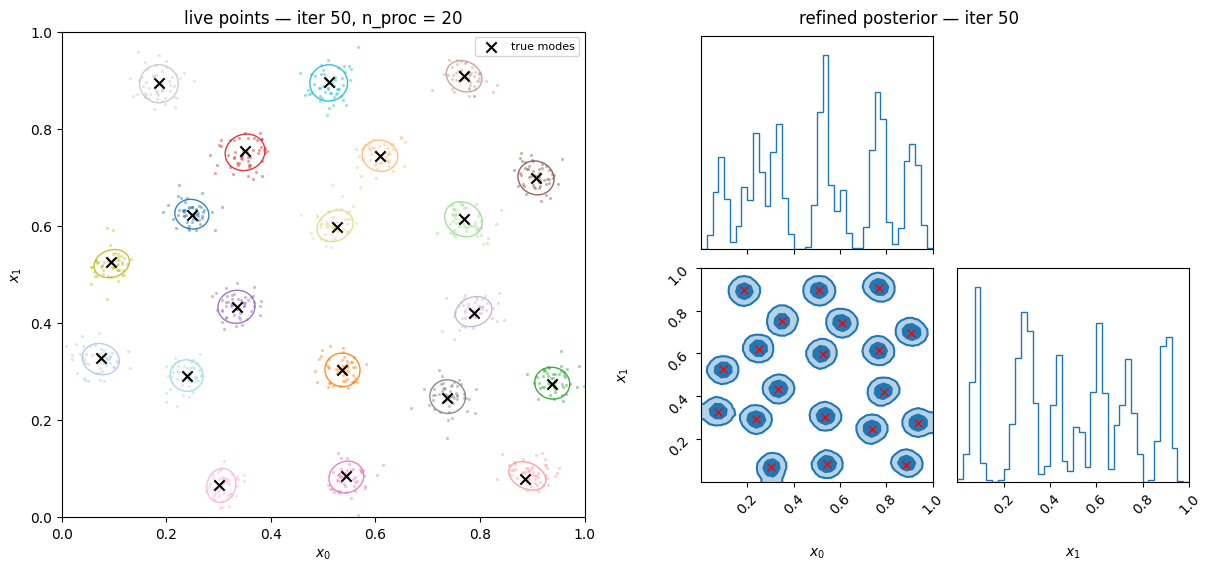

/Users/bertd/Documents/PhD/LISA/Projects/JAX-waveform/fewtrax/.venv/lib/python3.13/site-packages/corner/core.py:133: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(


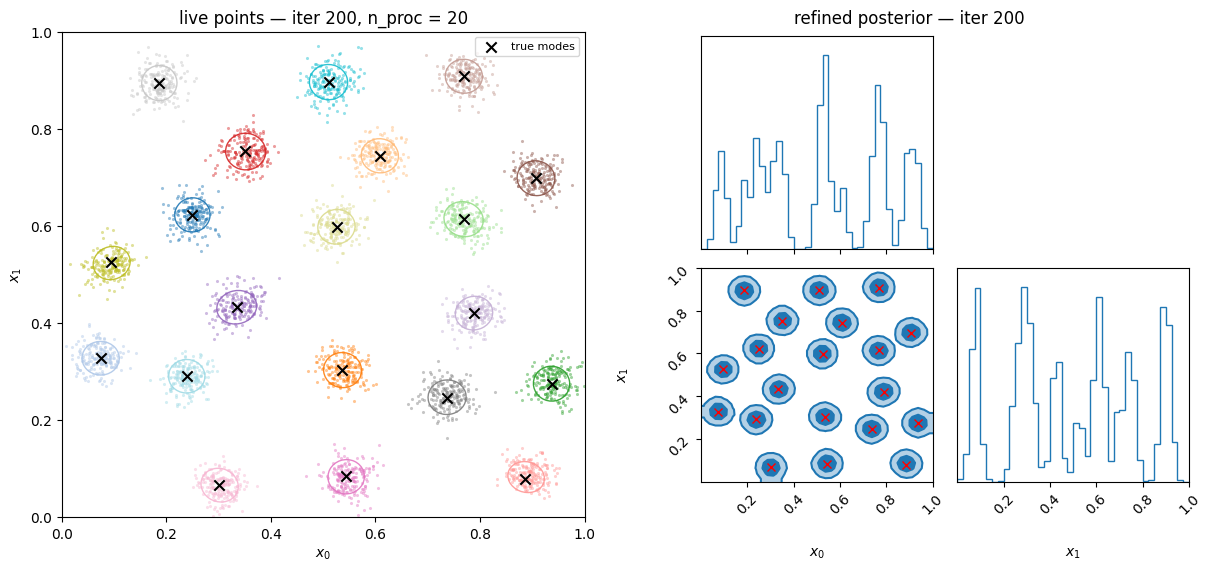

/Users/bertd/Documents/PhD/LISA/Projects/JAX-waveform/fewtrax/.venv/lib/python3.13/site-packages/corner/core.py:133: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(


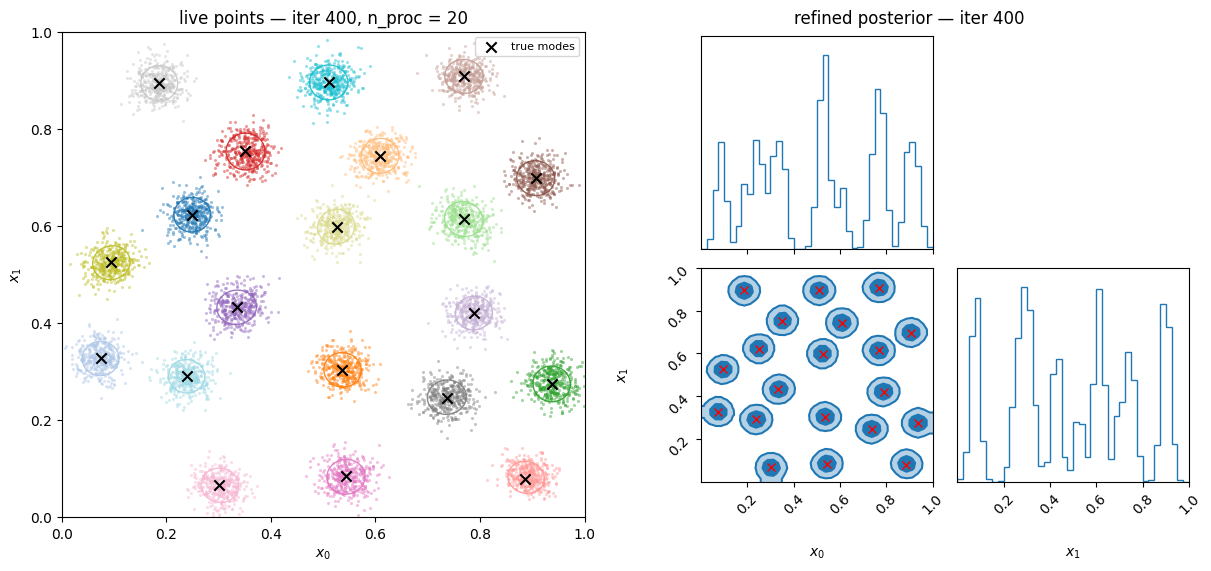

/Users/bertd/Documents/PhD/LISA/Projects/JAX-waveform/fewtrax/.venv/lib/python3.13/site-packages/corner/core.py:133: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(


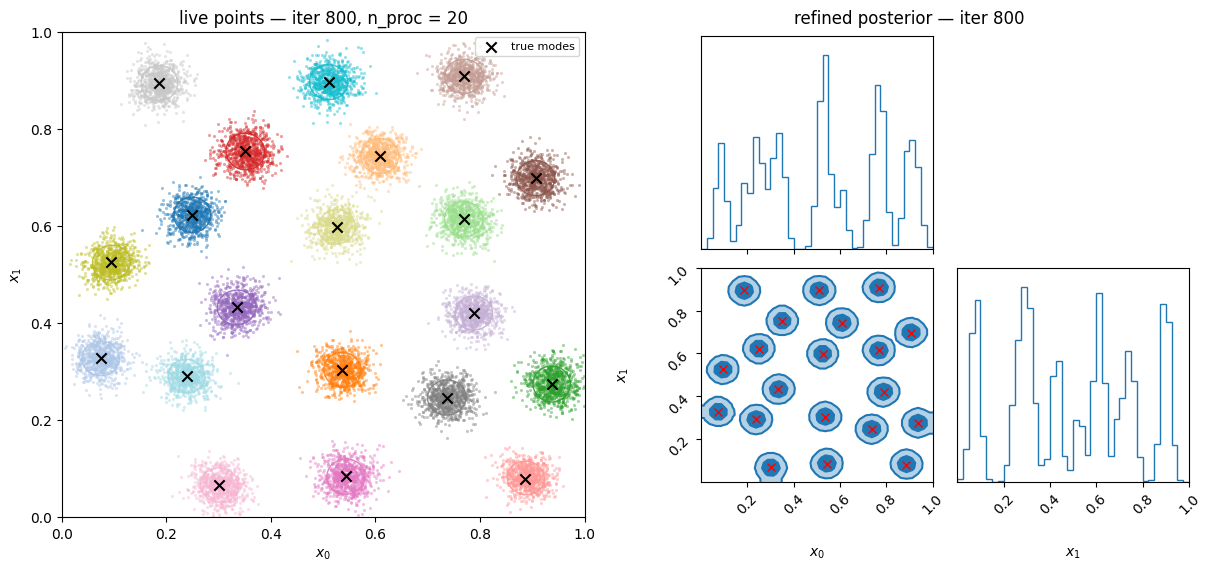

In [9]:
def plot_clustering_step(snap):
    fig = plt.figure(figsize=(12, 5.6), constrained_layout=True)
    subL, subR = fig.subfigures(1, 2, width_ratios=[1.0, 1.0])

    # LEFT: live points colored by surviving process + 2-sigma proposal ellipses.
    axL = subL.subplots()
    cmap = plt.get_cmap("tab20")
    for k, pts in enumerate(snap["proc_points"]):
        axL.scatter(pts[:, 0], pts[:, 1], s=5, color=cmap(k % 20), alpha=0.45, linewidths=0)
    for k, (mean, cov) in enumerate(zip(snap["means"], snap["covs"])):
        vals, vecs = np.linalg.eigh(cov)
        ang = np.degrees(np.arctan2(vecs[1, 0], vecs[0, 0]))
        w_, h_ = 2 * 2 * np.sqrt(np.maximum(vals, 0))   # 2-sigma
        axL.add_patch(Ellipse(mean, w_, h_, angle=ang, fill=False,
                              ec=cmap(k % 20), lw=1.0, alpha=0.9))
    axL.scatter(modes_np[:, 0], modes_np[:, 1], marker="x", c="k", s=55, zorder=5,
                label="true modes")
    axL.set(xlim=(0, 1), ylim=(0, 1), xlabel="$x_0$", ylabel="$x_1$",
            title=f"live points — iter {snap['it']}, n_proc = {snap['n_alive']}")
    axL.legend(loc="upper right", fontsize=8)

    # RIGHT: corner of the intermediate weighted posterior (corner reuses these axes).
    subR.subplots(ndim, ndim)
    weighted_corner(snap["samples"], weights=snap["weights"], truths=modes_np, fig=subR)
    subR.suptitle(f"refined posterior — iter {snap['it']}", fontsize=12)
    plt.show()

# Show a few clustering steps: the raw seeds, the first merge, then progressive refinement.
sel = [0, 1, 4, 8, len(snapshots) - 1]
for idx in sel:
    plot_clustering_step(snapshots[idx])

### 5.2 Inside the boundary correction: the optax (Adam) β-fit

When a process sits close to the edge of $[0,1]^d$, a chunk of its Gaussian proposal mass leaks outside the prior. PARIS-JAX corrects this with an **anisotropic shrink factor** $\boldsymbol{\beta}\in[0.5, 1]^d$ applied per axis to the proposal covariance, fitted by minimizing a smoothed truncated-Gaussian objective (`negative_BN_log_like`) with **projected Adam** (`optax.adam` + clip onto the box). This replaces the original Powell/BFGS path and is fully `jit`/`vmap`-able.

To make the behaviour visible we set up an *illustrative* single mode near the $x_0=0$ boundary (broad in $x_0$, narrow in $x_1$) and trace every Adam step. We expect $\beta_{x_0}$ (the boundary-facing axis) to move away from 1 while $\beta_{x_1}$ (the interior axis) stays put.

In [27]:
from parismc.optimization import negative_BN_log_like

def beta_adam_trace(diff, Adiff, W, W_sum, logdet, z, mean, ndim,
                    n_steps=100, lr=1e-2, slope=50.0, lower=0.5, upper=1.0 + 1e-3):
    """Re-run the find_max_beta optimization, but record beta and the loss at every step.

    This mirrors parismc.optimization.find_max_beta exactly (same objective, optimizer,
    learning rate and box projection). The only difference is that it just unpacks the scan
    in Python so we can plot the trajectory through the parameter space instead 
    of only returning the final beta.
    """
    obj = lambda b: negative_BN_log_like(b, diff, Adiff, W, W_sum, logdet, z, mean, ndim, slope=slope)
    grad = jax.jit(jax.value_and_grad(obj))
    beta = jnp.ones((ndim,))
    opt = optax.adam(lr)
    opt_state = opt.init(beta)
    betas, losses = [np.asarray(beta)], []
    for _ in range(n_steps):
        value, g = grad(beta)
        updates, opt_state = opt.update(g, opt_state, beta)
        beta = jnp.clip(optax.apply_updates(beta, updates), lower, upper)  # projection
        betas.append(np.asarray(beta))
        losses.append(float(value))
    return np.array(betas), np.array(losses)


out-of-bounds fraction at beta=1 : 0.246
fitted beta : [0.82245379 1.001     ]   (x0 axis shrinks, x1 axis ~unchanged)


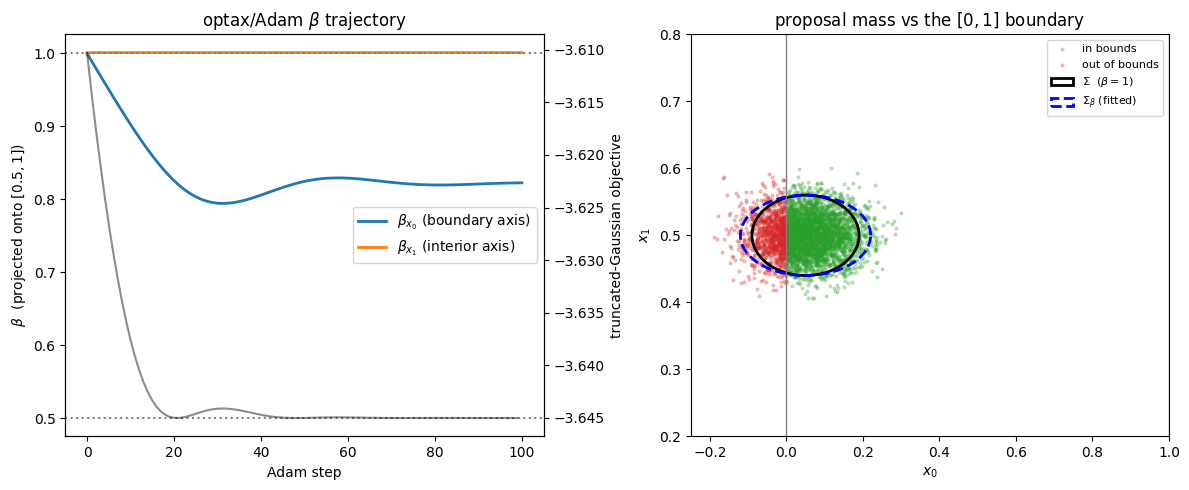

In [28]:
# start a random near-boundary process and run adam optimzer
key_b = jax.random.PRNGKey(7)
mean_b = jnp.array([0.05, 0.5])   # about 1 sigma from the x0 = 0 edge
cov_b = jnp.diag(jnp.array([0.07, 0.03]) ** 2)  # broad in x0, narrow in x1
z_b = jax.random.multivariate_normal(key_b, jnp.zeros(2), cov_b, (4096,))  # draw from proposal with zero mean

# invert covariance matrix
cov_inv_b = jnp.linalg.inv(cov_b)
W_b = jnp.full((z_b.shape[0],), 1.0 / z_b.shape[0]) # uniform weights (sum to 1)
Adiff_b = jnp.einsum('jk,ik->ji', cov_inv_b, z_b)       # (ndim, n)
logdet_b = jnp.linalg.slogdet(cov_b)[1]

betas, losses = beta_adam_trace(z_b, Adiff_b, W_b, 1.0, logdet_b, z_b, mean_b, 2)
oob = float(np.mean(np.any((np.asarray(z_b + mean_b) < 0) | (np.asarray(z_b + mean_b) > 1), axis=1)))
print(f"out-of-bounds fraction at beta=1 : {oob:.3f}")
print(f"fitted beta : {betas[-1]}   (x0 axis shrinks, x1 axis ~unchanged)")

# plottingthe beta trajectory and the fitted proposal vs the boundary in physical space.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# left side: beta trajectory 
# right side: the objective over Adam steps.
steps = np.arange(len(losses))
ax1.plot(betas[:, 0], color="C0", lw=2, label=r"$\beta_{x_0}$ (boundary axis)")
ax1.plot(betas[:, 1], color="C1", lw=2, label=r"$\beta_{x_1}$ (interior axis)")
ax1.axhline(0.5, ls=":", c="gray"); ax1.axhline(1.0, ls=":", c="gray")
ax1.set(xlabel="Adam step", ylabel=r"$\beta$  (projected onto $[0.5, 1]$)",
        title="optax/Adam $\\beta$ trajectory")
ax1b = ax1.twinx()
ax1b.plot(steps, losses, color="k", alpha=0.45, lw=1.5)
ax1b.set_ylabel("truncated-Gaussian objective", color="k")
ax1.legend(loc="center right")

# RIGHT: what the fitted beta does to the proposal vs the [0,1] boundary.
cand = np.asarray(z_b + mean_b)
inb = np.all((cand >= 0) & (cand <= 1), axis=1)
ax2.scatter(cand[inb, 0], cand[inb, 1], s=4, c="C2", alpha=0.25, label="in bounds")
ax2.scatter(cand[~inb, 0], cand[~inb, 1], s=4, c="C3", alpha=0.25, label="out of bounds")
for lbl, c, ls, B in [(r"$\Sigma$  ($\beta=1$)", "k", "-", np.ones(2)),
                      (r"$\Sigma_\beta$ (fitted)", "blue", "--", betas[-1])]:
    cov_s = np.asarray(cov_b) / B[:, None] / B[None, :]
    vals, vecs = np.linalg.eigh(cov_s)
    ang = np.degrees(np.arctan2(vecs[1, 0], vecs[0, 0]))
    w_, h_ = 2 * 2 * np.sqrt(vals)                       # 2-sigma
    ax2.add_patch(Ellipse(np.asarray(mean_b), w_, h_, angle=ang, fill=False, ec=c, ls=ls, lw=2, label=lbl))
for v in (0.0, 1.0):
    ax2.axvline(v, c="gray", lw=1); ax2.axhline(v, c="gray", lw=1)
ax2.set(xlim=(-0.25, 1.0), ylim=(0.2, 0.8), xlabel="$x_0$", ylabel="$x_1$",
        title="proposal mass vs the $[0,1]$ boundary")
ax2.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

### 5.3 Final posterior corner

The converged importance-weighted posterior as a `corner` plot. The 1-D marginals show all 20 peaks along each axis, and the 2-D panel recovers the full grid of modes (true centers in red).

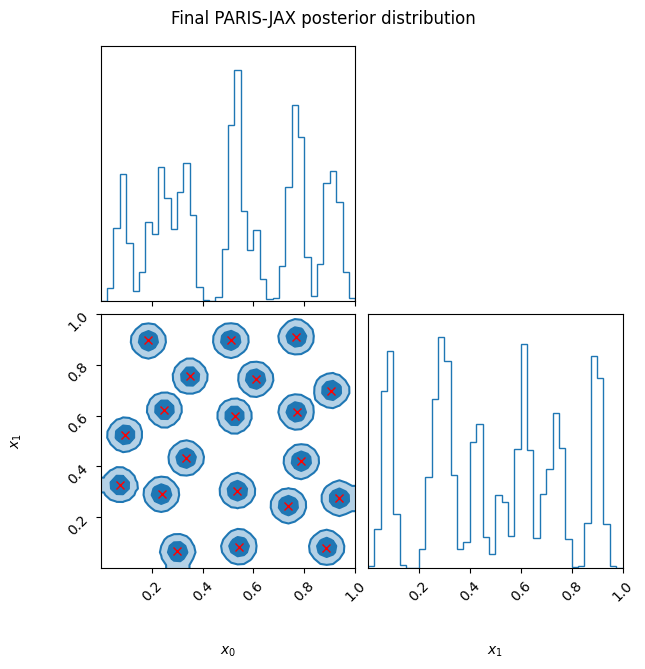

In [24]:
fig = plt.figure(figsize=(7, 7))
fig.subplots(ndim, ndim)
weighted_corner(samples, weights=weights, truths=modes_np, fig=fig,
                title="Final PARIS-JAX posterior distribution")
plt.show()

## 6. Prior transforms

`JaxSampler` does all of its work in the unit cube $[0,1]^d$, and `prior_transform` maps that working coordinate to your **physical** parameters. It is applied only when you extract results (`get_samples_with_weights`), so it never enters the density evaluation — `log_density_func` always sees $[0,1]^d$ points, and the transform just relabels the axes of the returned samples.

A prior transform is the **inverse CDF** (the percent-point function) of the prior: feed it a uniform variable $u\sim U(0,1)$ and it returns a variable with the desired distribution,

$$
x = T(u) = F^{-1}(u).
$$

Here we want $x$ to be Gaussian with mean $\mu=0.5$ and standard deviation $\sigma=0.163$, **truncated** to $[0,1]$. The inverse CDF of a truncated normal is

$$
T(u) = \mu + \sigma\,\Phi^{-1}\!\big(\Phi(a) + u\,[\Phi(b)-\Phi(a)]\big),
\qquad a=\tfrac{0-\mu}{\sigma},\; b=\tfrac{1-\mu}{\sigma},
$$

where $\Phi$ is the standard-normal CDF (`jax.scipy.special.ndtr`) and $\Phi^{-1}$ its inverse (`ndtri`). With $\mu\pm 3\sigma \approx [0.01, 0.99]$ the truncation barely bites — it trims the empirical std to $\approx 0.161$.

transformed mean = [0.50006319 0.49989417]   (target 0.5)
transformed std  = [0.16108437 0.16130953]   (target 0.163)


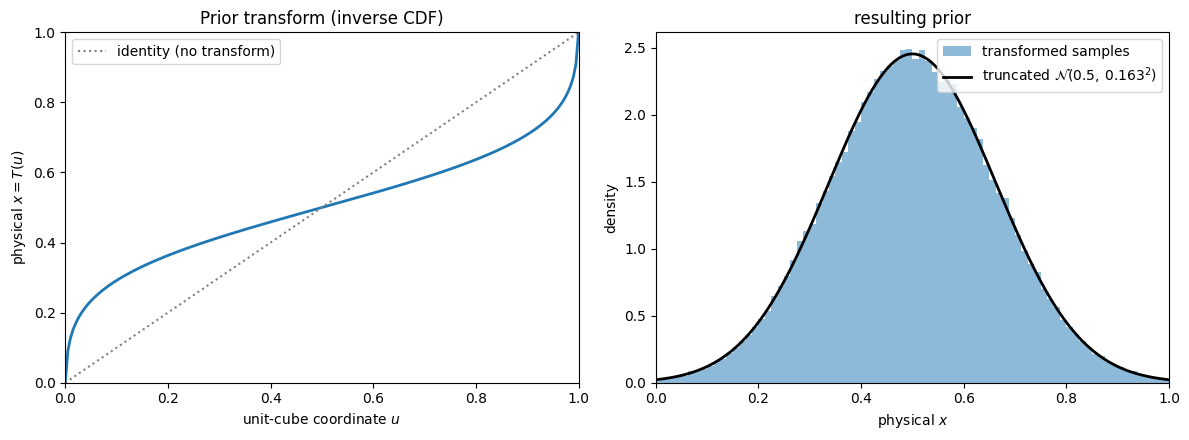

In [26]:
from jax.scipy.special import ndtr, ndtri   # standard-normal CDF and its inverse

prior_mean = 0.5
prior_std = 0.163

# Phi at the truncation edges, precomputed once.
_lo = ndtr((0.0 - prior_mean) / prior_std)
_hi = ndtr((1.0 - prior_mean) / prior_std)

# define the prior transformation
@jax.jit
def gaussian_prior_transform(u):
    """Map u ~ U([0,1]^d) -> N(prior_mean, prior_std^2) truncated to [0,1], per axis."""
    u = jnp.atleast_2d(u)
    return prior_mean + prior_std * ndtri(_lo + u * (_hi - _lo))


# sanity check: a uniform input should come out Gaussian with the requested statistics
u_demo = np.random.default_rng(0).uniform(size=(200_000, ndim))
x_demo = np.asarray(gaussian_prior_transform(jnp.asarray(u_demo)))
print(f"transformed mean = {x_demo.mean(0)}   (target {prior_mean})")
print(f"transformed std  = {x_demo.std(0)}   (target {prior_std})")

# create truncated Gaussian PDF to compare draws against
grid = np.linspace(0, 1, 400)
trunc_pdf = (np.exp(-0.5 * ((grid - prior_mean) / prior_std) ** 2)
             / (prior_std * np.sqrt(2 * np.pi))) / float(_hi - _lo)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
uu = np.linspace(0, 1, 200)
# Evolution of prior transform and the impact on the CDF in physical space. 
ax1.plot(uu, np.asarray(gaussian_prior_transform(jnp.asarray(uu)[:, None]))[:, 0], lw=2)
ax1.plot([0, 1], [0, 1], ls=":", c="gray", label="identity (no transform)")
ax1.set(xlabel="unit-cube coordinate $u$", ylabel="physical $x = T(u)$",
        title="Prior transform (inverse CDF)")
ax1.set_ylim([-0.0, 1.0])
ax1.set_xlim([-0.0, 1.0])
ax1.legend()

# histogram validating the prior transformation
ax2.hist(x_demo[:, 0], bins=80, density=True, alpha=0.5, label="transformed samples")
ax2.plot(grid, trunc_pdf, "k", lw=2, label=r"truncated $\mathcal{N}(0.5,\,0.163^2)$")
ax2.set(xlabel="physical $x$", ylabel="density", title="resulting prior")
ax2.set_xlim([0, 1])
ax2.legend()
plt.tight_layout()
plt.show()

### Attaching prior transform to the sampler

This section show how one should pass the prior transform at construction time. Because it only relabels the output, we can reuse the already-converged `state` from the earlier run and re-extract the samples in physical coordinates. The Gaussian transform pulls probability mass toward the centre, so modes near the edges of the cube are squeezed inward while the central modes barely move.

In [29]:
sampler_phys = JaxSampler(ndim, log_density, config, prior_transform=gaussian_prior_transform)
sampler_phys.state = state          # reuse the already-converged run from section 3
samples_phys, weights_phys = sampler_phys.get_samples_with_weights()
weights_phys = weights_phys / weights_phys.sum()
modes_phys = np.asarray(gaussian_prior_transform(modes))   # where the true modes land


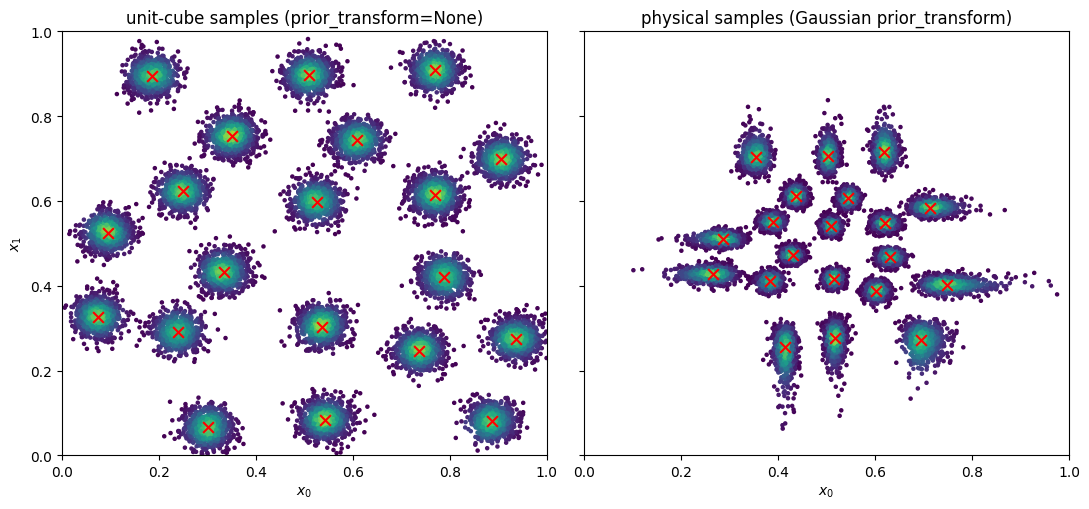

In [30]:

fig, (a0, a1) = plt.subplots(1, 2, figsize=(11, 5.2), sharex=True, sharey=True)
a0.scatter(samples[:, 0], samples[:, 1], c=weights, s=5, cmap="viridis")
a0.scatter(modes_np[:, 0], modes_np[:, 1], marker="x", c="red", s=60)
a0.set(title="unit-cube samples (prior_transform=None)", xlabel="$x_0$", ylabel="$x_1$")
a1.scatter(samples_phys[:, 0], samples_phys[:, 1], c=weights_phys, s=5, cmap="viridis")
a1.scatter(modes_phys[:, 0], modes_phys[:, 1], marker="x", c="red", s=60)
a1.set(title="physical samples (Gaussian prior_transform)", xlabel="$x_0$")
for ax in (a0, a1):
    ax.set(xlim=(0, 1), ylim=(0, 1))
plt.tight_layout()
plt.show()

Alternative (and statistically correct) route: fold the prior straight into the density. A Bayesian posterior is  p(x) ∝ L(x)·π(x), so  log p = log L + log π.  Here L is the 20-mode mixture and π = N(0.5, 0.163^2) truncated to [0,1].  We add the Gaussian log-prior (the U(0,1)/truncation factors are constants -> drop out; the box is enforced by boundary_limiting).  No prior_transform, because x already is the physical parameter.

folded-prior run: n_proc=20, logZ=-4.5558


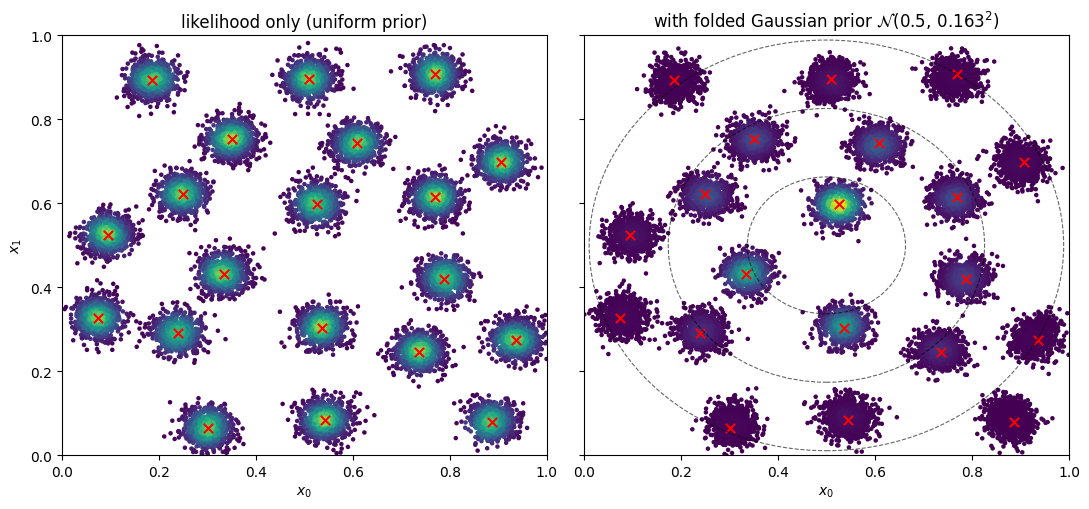

In [31]:

@jax.jit
def log_density_with_prior(x):
    x = jnp.atleast_2d(x)
    d = x[:, None, :] - modes[None, :, :]
    log_like = jax.scipy.special.logsumexp(-0.5 * jnp.sum((d / sigma) ** 2, axis=2), axis=1)
    log_prior = -0.5 * jnp.sum(((x - prior_mean) / prior_std) ** 2, axis=1)   # up to a constant
    return log_like + log_prior

sampler_post = JaxSampler(ndim, log_density_with_prior, config)   # prior_transform stays None
sampler_post.init_state(seed_points,
                        np.asarray(log_density_with_prior(jnp.asarray(seed_points))), init_cov)
state_post = sampler_post.run(num_iterations=800, merge_every=50, verbose=False)
samples_post, weights_post = sampler_post.get_samples_with_weights()
weights_post = weights_post / weights_post.sum()
print(f"folded-prior run: n_proc={int(np.asarray(state_post.alive).sum())}, "
      f"logZ={sampler_post.log_evidence():.4f}")


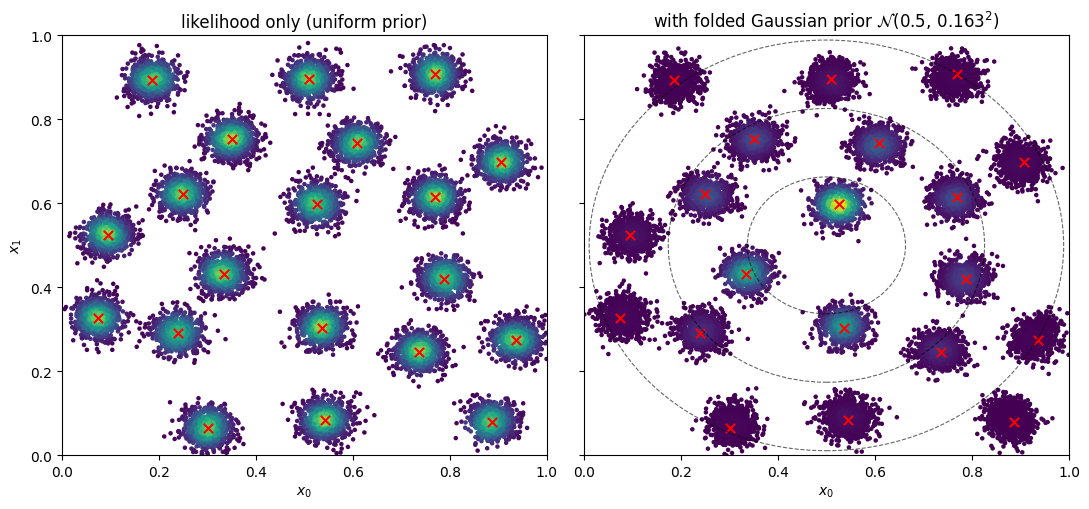

In [32]:

fig, (a0, a1) = plt.subplots(1, 2, figsize=(11, 5.2), sharex=True, sharey=True)
a0.scatter(samples[:, 0], samples[:, 1], c=weights, s=5, cmap="viridis")
a0.set(title="likelihood only (uniform prior)", xlabel="$x_0$", ylabel="$x_1$")
a1.scatter(samples_post[:, 0], samples_post[:, 1], c=weights_post, s=5, cmap="viridis")
a1.set(title=r"with folded Gaussian prior $\mathcal{N}(0.5,\,0.163^2)$", xlabel="$x_0$")
for ax in (a0, a1):
    ax.scatter(modes_np[:, 0], modes_np[:, 1], marker="x", c="red", s=45)
    ax.set(xlim=(0, 1), ylim=(0, 1))
for r in (1, 2, 3):   # prior 1/2/3-sigma rings on the posterior panel
    a1.add_patch(plt.Circle((prior_mean, prior_mean), r * prior_std,
                            fill=False, ec="k", ls="--", lw=0.8, alpha=0.6))
plt.tight_layout()
plt.show()

## 7. Notes

- **Reproducibility**: rerunning with the same `seed` gives identical results: the key is threaded through `SamplerState`, not read from global RNG state.
- **GPU**: if `log_density` resides on the GPU, the entire inner step (proposals + likelihood + weighting) runs as one fused on-device kernel. The only host work is the greedy merge on a small `(n_proc, n_proc)` matrix, which is tractable even for large `n_proc_max`.
- **Resuming / chunking**: `run(...)` returns the `SamplerState` pytree and stores it on `sampler.state`. Call `run(...)` again to continue, or save the pytree with your serializer of choice. (The diagnostics above use the same block loop `run` does internally, just recording a snapshot after each merge.)
